In [2]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# important libraries for the AI101 MINI PROJECT

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [4]:
df = pd.read_csv('Fish.csv')
df.head()



,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [5]:
#now we want to train model on 6 variables i.e. length1 length2 length3 height witdth and species
X_tr = df[['Species','Length1','Length2','Length3','Height','Width']]
y_te = df['Weight']
print('dataset shape:',df.shape)
print('\nany null:\n',df.isnull().sum())


dataset shape: (159, 7)

any null:
 Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64


In [6]:
# we have to study about OUTLIERS also therefore:
print('             OUTLIERS           ')
for col in ["Length1","Length2","Length3","Height","Width"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    l_bound = Q1-IQR*1.5
    u_bound = Q3+IQR*1.5

    outliers = df[
        (df[col]<l_bound)| # '|' act as union
        (df[col]>u_bound)
    ]

    print(f'\n  {col}')
    print('lower bound:',round(l_bound,2))
    print('upper bound:',round(u_bound,2))
    print('potential outliers:',len(outliers))

             OUTLIERS           

  Length1
lower bound: -1.43
upper bound: 53.18
potential outliers: 3

  Length2
lower bound: -0.75
upper bound: 57.25
potential outliers: 3

  Length3
lower bound: -1.6
upper bound: 64.4
potential outliers: 1

  Height
lower bound: -3.69
upper bound: 22.0
potential outliers: 0

  Width
lower bound: 0.09
upper bound: 8.88
potential outliers: 0


see here there are some potential outliers but we are not removing them because a large portion of data is perfectly valid; and also we need to look into the data before removing these outliers. after all these are fish and come in various sizes

In [7]:

# the Train and Test split

X_train,X_test,y_train,y_test = train_test_split(
    X_tr,y_te,
    test_size=0.20,
    random_state=42
)

In [8]:
#we have to prepocess data because species has the data type categorical so we have to convert it into something
#so that linear regression could comprehend
base_prepocessing = ColumnTransformer(transformers=
    [('species',OneHotEncoder(handle_unknown='ignore'),["Species"])],#onehotencoder does that to 
    remainder='passthrough'
)
base_model = Pipeline(steps=[
    ("prepocessing",base_prepocessing),
    ("Regression",LinearRegression())#our model does the prepocessing and then the performs the regression
])

In [9]:
#i have previously tested WITHOUT feature scaling(lets call it baseline)but we should also consider feature scaling in our model to
#yield better accuracy ,we would compare both of them.
scale_prepocessing = ColumnTransformer(transformers=[
    ("species",OneHotEncoder(handle_unknown="ignore"),["Species"]),
    ("numeric",StandardScaler(),["Length1","Length2","Length3","Height","Width"])],
    remainder="drop"
)
scaled_model = Pipeline(steps=[
    ('prepocessor',scale_prepocessing),
    ('regressor',LinearRegression())
])

In [10]:
base_model.fit(X_train,y_train)

scaled_model.fit(X_train,y_train)
#training done


base_pred = base_model.predict(X_test)

scaled_pred = scaled_model.predict(X_test)


In [11]:

#         evaluation metrics

def evaluation(name,model,predictions):

    train_r2 = model.score(X_train, y_train)
    test_r2 = r2_score(y_test, predictions)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    print(f"\n========== {name} ==========")

    print(f"Training R2 : {train_r2:.4f}")
    print(f"Testing R2  : {test_r2:.4f}")
    print(f"MAE         : {mae:.2f} g")
    print(f"MSE         : {mse:.2f}")
    print(f"RMSE        : {rmse:.2f} g")

    return train_r2, test_r2, mae, rmse

base_results = evaluation("Baseline Model",base_model,base_pred)

scaled_results = evaluation ("Scaled Model",scaled_model,scaled_pred)



========== Baseline Model ==========
Training R2 : 0.9286
Testing R2  : 0.9507
MAE         : 65.30 g
MSE         : 7007.38
RMSE        : 83.71 g

========== Scaled Model ==========
Training R2 : 0.9286
Testing R2  : 0.9507
MAE         : 65.30 g
MSE         : 7007.38
RMSE        : 83.71 g


Both Models produce the same results and have the same evaluation metrics 
i was expecting a better evaluation metrics for the scaled version but that is not the case because, in this, if the variables are scaled lets say by (*1000) so the coefficients of them are also scaled by(/1000) so there is effectively no effect

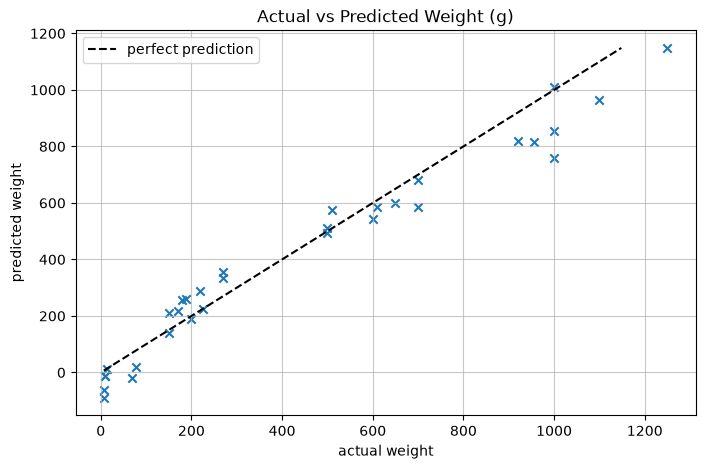

In [12]:
#        Training Plots 

#1 actual vs predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test,scaled_pred,marker="x")
plt.plot(
    [y_test.min(),scaled_pred.max()],
    [y_test.min(),scaled_pred.max()],
    linestyle = "--",
    color = "black",
    label = "perfect prediction"
)
plt.xlabel("actual weight")
plt.ylabel("predicted weight")
plt.grid(alpha=0.70)
plt.title("Actual vs Predicted Weight (g)")
plt.legend()

plt.show()

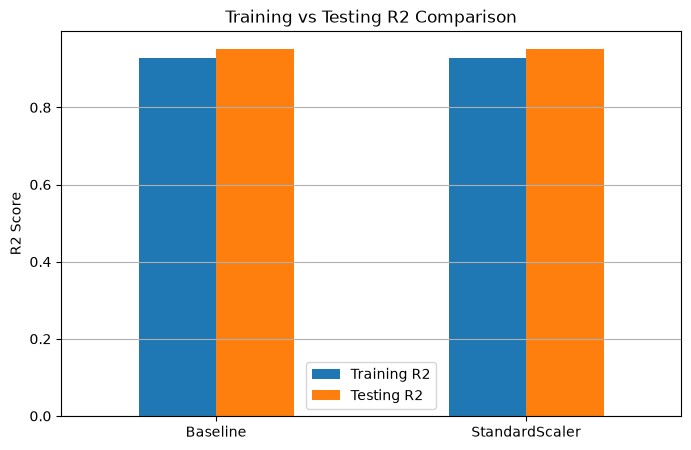

In [13]:
#2 train vs test r2 plot
results = pd.DataFrame(
    [base_results, scaled_results],
    columns=["Training R2", "Testing R2","MAE","MSE"],
    index=["Baseline", "StandardScaler"]
)
results[["Training R2", "Testing R2"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Training vs Testing R2 Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)#so the text appears in horizontal
plt.grid(axis="y")#horizontal grid appears instead of the standard square boxes
plt.show()

Effectively both models are same

In [14]:
#some sample predictions
sample = pd.DataFrame({
    "actual weight": y_test.to_numpy(),
    "predictd weight": scaled_pred
})

sample.head(10).round(2)

,actual weight,predictd weight
0,78.0,18.74
1,13.4,11.89
2,200.0,187.71
3,270.0,332.74
4,150.0,212.10
5,1000.0,757.76
6,7.0,-61.14
7,180.0,255.77
8,188.0,260.49
9,1250.0,1148.32


In [15]:
from sklearn.base import clone


def add_volume_proxy(features):
    return features.assign(
        VolumeProxy=features["Length3"] * features["Height"] * features["Width"]
    )


volume_model = clone(base_model)
volume_model.fit(add_volume_proxy(X_train), y_train)
volume_pred = volume_model.predict(add_volume_proxy(X_test))


def test_metrics(predictions):
    return {
        "MAE (g)": mean_absolute_error(y_test, predictions),
        "RMSE (g)": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R²": r2_score(y_test, predictions),
        "Negative predictions": int((predictions < 0).sum())
    }


comparison = pd.DataFrame(
    [test_metrics(base_pred), test_metrics(scaled_pred), test_metrics(volume_pred)],
    index=["Unscaled", "Scaled", "With volume proxy"]
)
comparison.round(4)


,MAE (g),RMSE (g),Test R²,Negative predictions
Unscaled,65.3001,83.7101,0.9507,5
Scaled,65.3001,83.7101,0.9507,5
With volume proxy,43.7334,58.2286,0.9762,2
